In [1]:
from pathlib import Path
import sys
import json
import hashlib
from collections import Counter

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from tqdm.auto import tqdm


PROJECT_ROOT = Path.cwd().parent

AID_ROOT = PROJECT_ROOT / "datasets" / "raw" / "AID"
NWPU_ROOT = PROJECT_ROOT / "datasets" / "raw" / "NWPU-RESISC45"

METADATA_ROOT = PROJECT_ROOT / "datasets" / "metadata"
METADATA_ROOT.mkdir(parents=True, exist_ok=True)

print("Project root :", PROJECT_ROOT)
print("AID root     :", AID_ROOT)
print("NWPU root    :", NWPU_ROOT)

assert AID_ROOT.exists()
assert NWPU_ROOT.exists()

Project root : c:\Skripsi\Project\PyCIL
AID root     : c:\Skripsi\Project\PyCIL\datasets\raw\AID
NWPU root    : c:\Skripsi\Project\PyCIL\datasets\raw\NWPU-RESISC45


c:\Skripsi\Project\PyCIL\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png"}


def scan_dataset(dataset_root, dataset_name):
    rows = []
    corrupt_files = []

    class_dirs = sorted([
        p for p in dataset_root.iterdir()
        if p.is_dir()
    ])

    for class_dir in tqdm(
        class_dirs,
        desc=f"Scanning {dataset_name}"
    ):
        image_paths = sorted([
            p for p in class_dir.rglob("*")
            if p.is_file()
            and p.suffix.lower() in IMAGE_EXTENSIONS
        ])

        for image_path in image_paths:
            relative_path = image_path.relative_to(dataset_root)

            try:
                with Image.open(image_path) as img:
                    width, height = img.size
                    mode = img.mode
                    image_format = img.format

                    # Check basic file integrity
                    img.verify()

                rows.append({
                    "dataset": dataset_name,
                    "relative_path": str(relative_path),
                    "class_name": class_dir.name,
                    "filename": image_path.name,
                    "extension": image_path.suffix.lower(),
                    "width": width,
                    "height": height,
                    "mode": mode,
                    "format": image_format,
                    "file_size_bytes": image_path.stat().st_size,
                    "is_valid": True,
                })

            except Exception as e:
                corrupt_files.append({
                    "dataset": dataset_name,
                    "relative_path": str(relative_path),
                    "class_name": class_dir.name,
                    "error": repr(e),
                })

    return pd.DataFrame(rows), pd.DataFrame(corrupt_files)

In [3]:
aid_df, aid_corrupt = scan_dataset(
    AID_ROOT,
    "AID"
)

nwpu_df, nwpu_corrupt = scan_dataset(
    NWPU_ROOT,
    "NWPU-RESISC45"
)

Scanning NWPU-RESISC45: 100%|██████████| 45/45 [03:19<00:00,  4.44s/it]


In [4]:
print("=== AID ===")
print("Classes :", aid_df["class_name"].nunique())
print("Images  :", len(aid_df))
print("Corrupt :", len(aid_corrupt))

print()

print("=== NWPU-RESISC45 ===")
print("Classes :", nwpu_df["class_name"].nunique())
print("Images  :", len(nwpu_df))
print("Corrupt :", len(nwpu_corrupt))

=== AID ===
Classes : 30
Images  : 10000
Corrupt : 0

=== NWPU-RESISC45 ===
Classes : 45
Images  : 31500
Corrupt : 0


In [5]:
assert aid_df["class_name"].nunique() == 30
assert len(aid_df) == 10000

assert nwpu_df["class_name"].nunique() == 45
assert len(nwpu_df) == 31500

assert len(aid_corrupt) == 0
assert len(nwpu_corrupt) == 0

print("Dataset basic validation: PASSED")

Dataset basic validation: PASSED


In [6]:
aid_class_counts = (
    aid_df
    .groupby("class_name")
    .size()
    .sort_values()
)

aid_class_counts

class_name
BaseballField        220
Church               240
Forest               250
RailwayStation       260
Center               260
Meadow               280
MediumResidential    290
Stadium              290
Resort               290
School               300
SparseResidential    300
Desert               300
BareLand             310
Square               330
Mountain             340
Commercial           350
Park                 350
Airport              360
StorageTanks         360
Bridge               360
Playground           370
Farmland             370
Port                 380
Industrial           390
Parking              390
Beach                400
River                410
DenseResidential     410
Pond                 420
Viaduct              420
dtype: int64

In [7]:
print("Min   :", aid_class_counts.min())
print("Max   :", aid_class_counts.max())
print("Mean  :", aid_class_counts.mean())
print("Median:", aid_class_counts.median())
print("Std   :", aid_class_counts.std())

Min   : 220
Max   : 420
Mean  : 333.3333333333333
Median: 345.0
Std   : 57.79472194809376


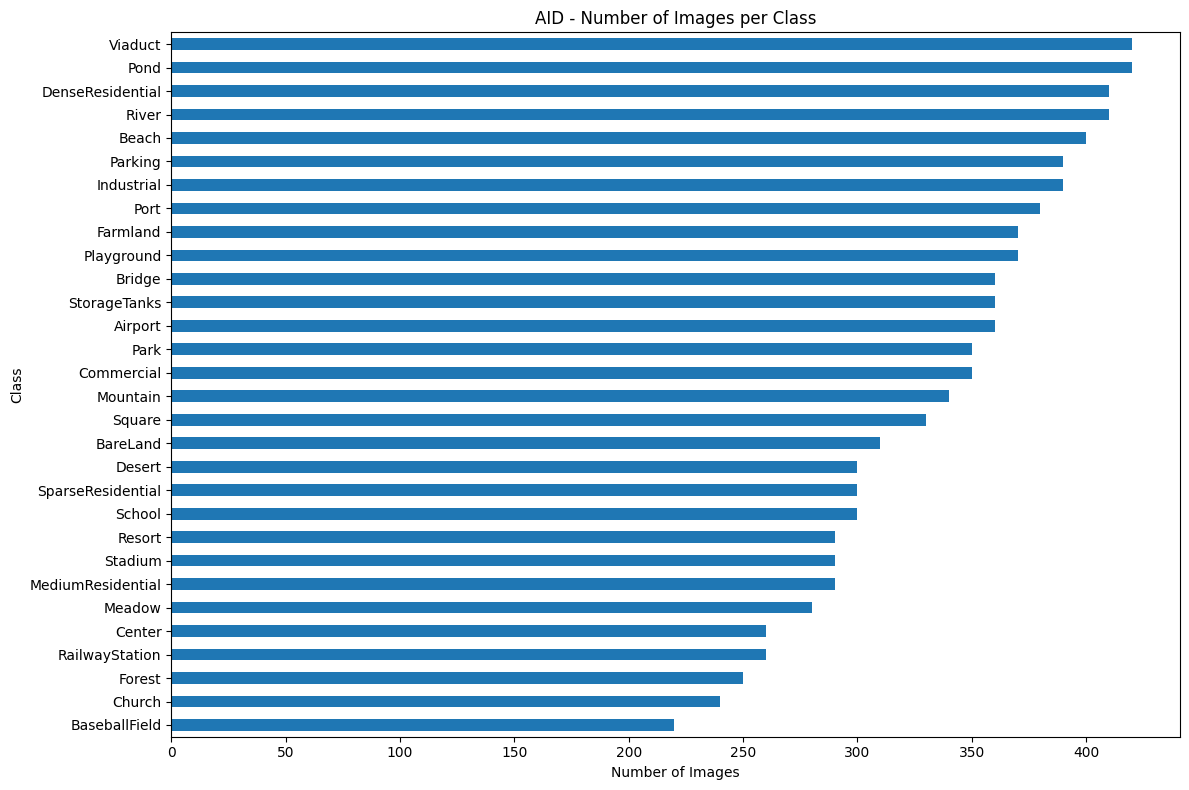

In [8]:
plt.figure(figsize=(12, 8))

aid_class_counts.sort_values().plot(
    kind="barh"
)

plt.title("AID - Number of Images per Class")
plt.xlabel("Number of Images")
plt.ylabel("Class")

plt.tight_layout()
plt.show()

In [9]:
nwpu_class_counts = (
    nwpu_df
    .groupby("class_name")
    .size()
    .sort_values()
)

nwpu_class_counts

class_name
airplane                 700
mobile_home_park         700
mountain                 700
overpass                 700
palace                   700
parking_lot              700
railway                  700
railway_station          700
rectangular_farmland     700
river                    700
roundabout               700
runway                   700
sea_ice                  700
ship                     700
snowberg                 700
sparse_residential       700
stadium                  700
storage_tank             700
tennis_court             700
terrace                  700
medium_residential       700
thermal_power_station    700
meadow                   700
island                   700
airport                  700
baseball_diamond         700
basketball_court         700
beach                    700
bridge                   700
chaparral                700
church                   700
circular_farmland        700
cloud                    700
commercial_area          700
den

In [10]:
print(nwpu_class_counts.value_counts())

assert nwpu_class_counts.nunique() == 1
assert nwpu_class_counts.iloc[0] == 700

print("NWPU class distribution is perfectly balanced.")

700    45
Name: count, dtype: int64
NWPU class distribution is perfectly balanced.


In [11]:
aid_resolution = (
    aid_df
    .groupby(["width", "height"])
    .size()
    .sort_values(ascending=False)
)

aid_resolution

width  height
600    600       10000
dtype: int64

In [12]:
nwpu_resolution = (
    nwpu_df
    .groupby(["width", "height"])
    .size()
    .sort_values(ascending=False)
)

nwpu_resolution

width  height
256    256       31500
dtype: int64

In [13]:
print("AID resolutions:")
display(aid_resolution)

print("\nNWPU resolutions:")
display(nwpu_resolution)

AID resolutions:


width  height
600    600       10000
dtype: int64


NWPU resolutions:


width  height
256    256       31500
dtype: int64

In [14]:
print("AID modes:")
print(aid_df["mode"].value_counts())

print()

print("NWPU modes:")
print(nwpu_df["mode"].value_counts())

AID modes:
mode
RGB    10000
Name: count, dtype: int64

NWPU modes:
mode
RGB    31500
Name: count, dtype: int64


In [15]:
print("AID extensions:")
print(aid_df["extension"].value_counts())

print()

print("NWPU extensions:")
print(nwpu_df["extension"].value_counts())

AID extensions:
extension
.jpg    10000
Name: count, dtype: int64

NWPU extensions:
extension
.jpg    31500
Name: count, dtype: int64


In [16]:
print("AID formats:")
print(aid_df["format"].value_counts())

print()

print("NWPU formats:")
print(nwpu_df["format"].value_counts())

AID formats:
format
JPEG    9532
PNG      468
Name: count, dtype: int64

NWPU formats:
format
JPEG    31500
Name: count, dtype: int64


In [17]:
aid_classes = sorted(
    aid_df["class_name"].unique()
)

nwpu_classes = sorted(
    nwpu_df["class_name"].unique()
)

aid_class_to_id = {
    class_name: idx
    for idx, class_name in enumerate(aid_classes)
}

nwpu_class_to_id = {
    class_name: idx
    for idx, class_name in enumerate(nwpu_classes)
}

In [18]:
aid_df["original_class_id"] = (
    aid_df["class_name"]
    .map(aid_class_to_id)
)

nwpu_df["original_class_id"] = (
    nwpu_df["class_name"]
    .map(nwpu_class_to_id)
)

In [19]:
print("AID:")
for name, idx in aid_class_to_id.items():
    print(f"{idx:2d} -> {name}")

print("\nNWPU:")
for name, idx in nwpu_class_to_id.items():
    print(f"{idx:2d} -> {name}")

AID:
 0 -> Airport
 1 -> BareLand
 2 -> BaseballField
 3 -> Beach
 4 -> Bridge
 5 -> Center
 6 -> Church
 7 -> Commercial
 8 -> DenseResidential
 9 -> Desert
10 -> Farmland
11 -> Forest
12 -> Industrial
13 -> Meadow
14 -> MediumResidential
15 -> Mountain
16 -> Park
17 -> Parking
18 -> Playground
19 -> Pond
20 -> Port
21 -> RailwayStation
22 -> Resort
23 -> River
24 -> School
25 -> SparseResidential
26 -> Square
27 -> Stadium
28 -> StorageTanks
29 -> Viaduct

NWPU:
 0 -> airplane
 1 -> airport
 2 -> baseball_diamond
 3 -> basketball_court
 4 -> beach
 5 -> bridge
 6 -> chaparral
 7 -> church
 8 -> circular_farmland
 9 -> cloud
10 -> commercial_area
11 -> dense_residential
12 -> desert
13 -> forest
14 -> freeway
15 -> golf_course
16 -> ground_track_field
17 -> harbor
18 -> industrial_area
19 -> intersection
20 -> island
21 -> lake
22 -> meadow
23 -> medium_residential
24 -> mobile_home_park
25 -> mountain
26 -> overpass
27 -> palace
28 -> parking_lot
29 -> railway
30 -> railway_station
3

### Exact Image Duplication check

In [20]:
def sha256_file(path, chunk_size=1024 * 1024):
    sha = hashlib.sha256()

    with open(path, "rb") as f:
        while True:
            chunk = f.read(chunk_size)

            if not chunk:
                break

            sha.update(chunk)

    return sha.hexdigest()

In [21]:
aid_hashes = []

for relative_path in tqdm(
    aid_df["relative_path"],
    desc="Hashing AID"
):
    full_path = AID_ROOT / relative_path
    aid_hashes.append(
        sha256_file(full_path)
    )

aid_df["sha256"] = aid_hashes

Hashing AID: 100%|██████████| 10000/10000 [00:15<00:00, 637.88it/s]


In [22]:
nwpu_hashes = []

for relative_path in tqdm(
    nwpu_df["relative_path"],
    desc="Hashing NWPU"
):
    full_path = NWPU_ROOT / relative_path
    nwpu_hashes.append(
        sha256_file(full_path)
    )

nwpu_df["sha256"] = nwpu_hashes

Hashing NWPU: 100%|██████████| 31500/31500 [00:25<00:00, 1246.27it/s]


In [23]:
aid_duplicates = aid_df[
    aid_df.duplicated(
        subset="sha256",
        keep=False
    )
].sort_values("sha256")

nwpu_duplicates = nwpu_df[
    nwpu_df.duplicated(
        subset="sha256",
        keep=False
    )
].sort_values("sha256")

In [24]:
print(
    "AID exact duplicate rows:",
    len(aid_duplicates)
)

print(
    "NWPU exact duplicate rows:",
    len(nwpu_duplicates)
)

AID exact duplicate rows: 0
NWPU exact duplicate rows: 16


### Inter Class Duplication

In [25]:
def cross_class_duplicates(df):
    duplicate_hashes = (
        df.groupby("sha256")["class_name"]
        .nunique()
    )

    problematic_hashes = duplicate_hashes[
        duplicate_hashes > 1
    ].index

    return df[
        df["sha256"].isin(problematic_hashes)
    ].sort_values(
        ["sha256", "class_name"]
    )

In [26]:
aid_cross_class_duplicates = cross_class_duplicates(
    aid_df
)

nwpu_cross_class_duplicates = cross_class_duplicates(
    nwpu_df
)

print(
    "AID cross-class duplicate rows:",
    len(aid_cross_class_duplicates)
)

print(
    "NWPU cross-class duplicate rows:",
    len(nwpu_cross_class_duplicates)
)

AID cross-class duplicate rows: 0
NWPU cross-class duplicate rows: 0


### Raw Manifest

In [27]:
aid_manifest_path = (
    METADATA_ROOT /
    "aid_raw_manifest.csv"
)

nwpu_manifest_path = (
    METADATA_ROOT /
    "nwpu_raw_manifest.csv"
)

aid_df.to_csv(
    aid_manifest_path,
    index=False
)

nwpu_df.to_csv(
    nwpu_manifest_path,
    index=False
)

print("Saved:")
print(aid_manifest_path)
print(nwpu_manifest_path)

Saved:
c:\Skripsi\Project\PyCIL\datasets\metadata\aid_raw_manifest.csv
c:\Skripsi\Project\PyCIL\datasets\metadata\nwpu_raw_manifest.csv


In [28]:
with open(
    METADATA_ROOT / "aid_class_mapping.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        aid_class_to_id,
        f,
        indent=4
    )


with open(
    METADATA_ROOT / "nwpu_class_mapping.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        nwpu_class_to_id,
        f,
        indent=4
    )

In [29]:
audit_summary = {
    "AID": {
        "num_classes": int(
            aid_df["class_name"].nunique()
        ),
        "num_images": int(
            len(aid_df)
        ),
        "corrupt_files": int(
            len(aid_corrupt)
        ),
        "exact_duplicate_rows": int(
            len(aid_duplicates)
        ),
        "cross_class_duplicate_rows": int(
            len(aid_cross_class_duplicates)
        ),
    },

    "NWPU_RESISC45": {
        "num_classes": int(
            nwpu_df["class_name"].nunique()
        ),
        "num_images": int(
            len(nwpu_df)
        ),
        "corrupt_files": int(
            len(nwpu_corrupt)
        ),
        "exact_duplicate_rows": int(
            len(nwpu_duplicates)
        ),
        "cross_class_duplicate_rows": int(
            len(nwpu_cross_class_duplicates)
        ),
    }
}

audit_summary

{'AID': {'num_classes': 30,
  'num_images': 10000,
  'corrupt_files': 0,
  'exact_duplicate_rows': 0,
  'cross_class_duplicate_rows': 0},
 'NWPU_RESISC45': {'num_classes': 45,
  'num_images': 31500,
  'corrupt_files': 0,
  'exact_duplicate_rows': 16,
  'cross_class_duplicate_rows': 0}}

In [30]:
with open(
    METADATA_ROOT / "dataset_audit_summary.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        audit_summary,
        f,
        indent=4
    )

### Check duplicate

In [31]:
duplicate_summary = (
    nwpu_duplicates
    .groupby("sha256")
    .agg(
        class_name=("class_name", "first"),
        duplicate_count=("relative_path", "count"),
        files=("relative_path", list),
    )
    .reset_index()
)

duplicate_summary

,sha256,class_name,duplicate_count,files
0,0a4d80dd498029f027c9e8ec5cbff130d48365e7adfe56...,airport,2,"[airport\airport_118.jpg, airport\airport_315...."
1,172af6b6c5897ab903b340c6a0200816fde5147724c05f...,palace,2,"[palace\palace_224.jpg, palace\palace_439.jpg]"
2,61b6a3d9edd9c1ff6c4fbb07a5bf8e1b0812a9cad6da09...,airport,2,"[airport\airport_050.jpg, airport\airport_420...."
3,a444df1df80be8a850a48cc88d9481dd4942628fff6795...,palace,2,"[palace\palace_595.jpg, palace\palace_669.jpg]"
4,b0e156fd5615364a95294af398b503c3f3abd34f40050b...,airport,2,"[airport\airport_243.jpg, airport\airport_397...."
5,c18c7cba2e9c7c65d000304b251248fa7e8d205266ace9...,airport,2,"[airport\airport_361.jpg, airport\airport_509...."
6,df386f9c782d1a78e35974160313dffa1e489bdbc058ad...,airport,2,"[airport\airport_064.jpg, airport\airport_527...."
7,fbd844f1e344f92cdc4eb2984b9822188fa4105fabd29f...,airport,2,"[airport\airport_289.jpg, airport\airport_635...."


In [32]:
print("Number of duplicate groups :", len(duplicate_summary))
print(
    "Duplicate group sizes       :",
    duplicate_summary["duplicate_count"].value_counts().sort_index()
)

print(
    "Extra duplicate images      :",
    (duplicate_summary["duplicate_count"] - 1).sum()
)

Number of duplicate groups : 8
Duplicate group sizes       : duplicate_count
2    8
Name: count, dtype: int64
Extra duplicate images      : 8
